In [12]:
import sys
sys.path.append("..") 

import matplotlib.pyplot as plt
from app.generators.synthetic import generate_activities

In [14]:
activities = generate_activities()
session = [a for a in activities if a.kind == "intervals"][0]
data_frame = session.samples
data_frame["minute"] = data_frame.index / 60 

print(session.start, len(data_frame), "seconds")
data_frame.head()

2026-08-26 07:00:00 3000 seconds


,timestamp,heart_rate,speed,distance,minute
0,2026-08-26 07:00:00,136,2.56,2.6,0.000000
1,2026-08-26 07:00:01,136,2.56,5.1,0.016667
2,2026-08-26 07:00:02,136,2.56,7.7,0.033333
3,2026-08-26 07:00:03,136,2.56,10.2,0.050000
4,2026-08-26 07:00:04,136,2.56,12.8,0.066667


## Speed and heart rate

Speed on top, heart rate below, sharing the same time axis.

If the data were realistic, speed would change almost immediately at the start of each
interval, while heart rate would need 30-60 s to catch up
Here both curves have exactly the same shape

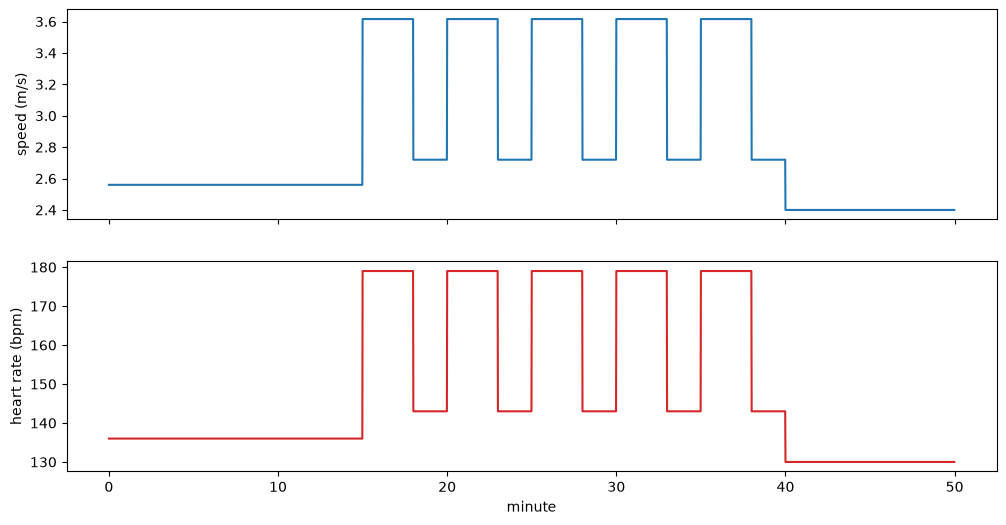

In [15]:
figure, (ax_speed, ax_hr) = plt.subplots(2, 1, figsize=(12, 6), sharex = True)

ax_speed.plot(data_frame["minute"], data_frame["speed"])
ax_speed.set_ylabel("speed (m/s)")

ax_hr.plot(data_frame["minute"], data_frame["heart_rate"], color = "tab:red")
ax_hr.set_ylabel("heart rate (bpm)")
ax_hr.set_xlabel("minute")

plt.show()

In [ ]:
data_frame.loc[895:910, ["timestamp", "speed", "heart_rate"]]

,timestamp,speed,heart_rate
895,2026-08-26 07:14:55,2.560,136
896,2026-08-26 07:14:56,2.560,136
897,2026-08-26 07:14:57,2.560,136
898,2026-08-26 07:14:58,2.560,136
899,2026-08-26 07:14:59,2.560,136
900,2026-08-26 07:15:00,3.616,179
901,2026-08-26 07:15:01,3.616,179
902,2026-08-26 07:15:02,3.616,179
903,2026-08-26 07:15:03,3.616,179
904,2026-08-26 07:15:04,3.616,179


## Conclusion

The generator sets heart rate directly to the target of each segment, so HR jumps
from 136 to 179 bpm in one second when an interval starts. A real heart doesn't do that

This doesn't matter much for ACWR (daily load changes only a little), but it makes
the HR chart look unrealistic and overestimates time in Z5.
Next step: let HR approach the target gradually. (see issue "Realistic HR curve in synthetic data").